# 1. Data exploration and patient-level split

**Project goal:** train a deep learning model that classifies **optical coherence tomography (OCT)** images of the retina by disease, and check that the model focuses on regions that make clinical sense.

**What is OCT?** It is an imaging technique that produces a cross-sectional "slice" of the retina, similar to an ultrasound but using light. It is widely used to diagnose and monitor retinal diseases.

**Dataset:** [OCTDL](https://data.mendeley.com/datasets/sncdhf53xc/4) (Kulyabin et al., *Scientific Data*, 2024), with more than 2,000 OCT images labelled by disease. The folders correspond to:

| Code | Disease |
|---|---|
| AMD | Age-related macular degeneration |
| DME | Diabetic macular edema |
| ERM | Epiretinal membrane |
| NO | Normal retina |
| RAO | Retinal artery occlusion |
| RVO | Retinal vein occlusion |
| VID | Vitreomacular interface disease |

This notebook explores the dataset and prepares the **train / validation / test split**.

In [3]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # so the repo scripts can be imported

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from prepare_data import build_manifest

# Edit these two paths to point to your local copy of the data
DATA_DIR = "OCTDL"
CSV_PATH = "OCTDL_labels.csv"
SEED = 42

## Metadata
The CSV distributed with the dataset indicates which patient each image belongs to. This information is essential for building a leakage-free split.

In [4]:
meta = pd.read_csv(CSV_PATH)
print(f"{len(meta)} rows in the metadata CSV")
meta.head()

2064 rows in the metadata CSV


,file_name,disease,subcategory,condition,patient_id,eye,sex,year,image_width,image_hight
0,amd_1047099_1,AMD,intermediate,MNV_suspected,1047099,0,0,0,1101,410
1,amd_1047099_2,AMD,intermediate,MNV_suspected,1047099,0,0,0,731,265
2,amd_1047099_3,AMD,intermediate,MNV_suspected,1047099,0,0,0,1100,410
3,amd_1047099_4,AMD,intermediate,MNV_suspected,1047099,0,0,0,882,321
4,amd_1084498_1,AMD,late,MNV,1084498,0,0,0,882,321


In [5]:
df = build_manifest(DATA_DIR, CSV_PATH, seed=SEED)
print(f"{len(df)} images from {df['patient_id'].nunique()} distinct patients")

2064 images from 820 distinct patients


## Images and patients per disease

,images,patients
label,,
AMD,1231,421
NO,332,110
ERM,155,71
DME,147,107
RVO,101,50
VID,76,51
RAO,22,11


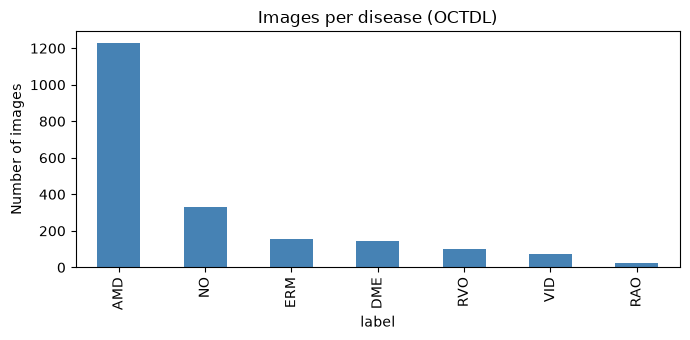

In [6]:
counts = (df.groupby("label")
            .agg(images=("path", "count"), patients=("patient_id", "nunique"))
            .sort_values("images", ascending=False))
display(counts)

ax = counts["images"].plot(kind="bar", figsize=(7, 3.5), color="steelblue")
ax.set_ylabel("Number of images")
ax.set_title("Images per disease (OCTDL)")
plt.tight_layout()
plt.show()

**Observation:** the dataset is **strongly imbalanced**: some diseases have many more images than others. If this is ignored, the model tends to get the frequent diseases right and neglect the rare ones. This is compensated for later by giving more weight to classes with few images during training.

## Example images

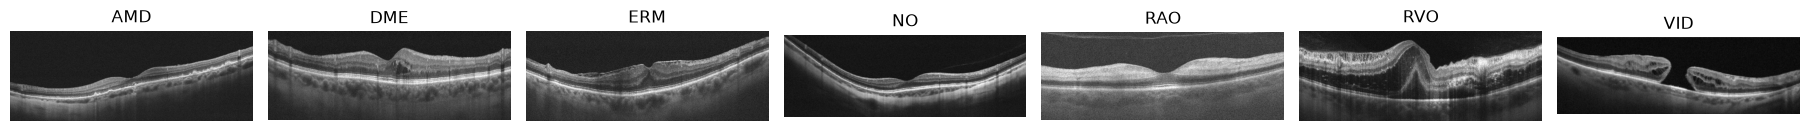

In [7]:
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(1, len(classes), figsize=(2.6 * len(classes), 2.8))
for ax, c in zip(axes, classes):
    path = df[df.label == c].iloc[0]["path"]
    ax.imshow(Image.open(path).convert("L"), cmap="gray")
    ax.set_title(c)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Patient-level split (avoiding data leakage)

A single patient can contribute several very similar images. If images were split randomly between training and test sets, the model would be tested on images almost identical to ones it already learned from, and the results would look better than they really are (**data leakage**).

To avoid this, the split is done **by patient**: all images from one patient go to the same set. The split is roughly 60% training, 20% validation (used to pick the best model) and 20% test (final evaluation on data the model has never seen), keeping a similar proportion of diseases in each set.

In [8]:
print(pd.crosstab(df["label"], df["split"]))

n_split = df.groupby("patient_id")["split"].nunique()
print("\nPatients present in more than one set:", int((n_split > 1).sum()))

df.groupby("split")["patient_id"].nunique().rename("patients per set")

split  test  train  val
label                  
AMD     246    739  246
DME      29     89   29
ERM      31     93   31
NO       66    199   67
RAO       7     11    4
RVO      20     61   20
VID      15     45   16

Patients present in more than one set: 0


split
test     162
train    494
val      164
Name: patients per set, dtype: int64

In [9]:
out = Path.cwd().parent / "data" / "manifest.csv"
out.parent.mkdir(exist_ok=True)
df[["path", "label", "patient_id", "split"]].to_csv(out, index=False)
print("Manifest saved.")

Manifest saved.


## Takeaways from this stage

- The dataset contains several diseases with very uneven numbers of images.
- The split was made by patient, and it was verified that no patient appears in more than one set.
- Diseases with very few images may end up with very few test cases, which limits the reliability of the metrics for those classes.

Next step: model training (notebook `02_model_and_results.ipynb`).